## Strava Project

#### Loading and preparing the data

In [63]:
# IMPORT PACKAGES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from xgboost import XGBRegressor
import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
from sklearn.model_selection import GridSearchCV

In [2]:
# UPLOAD DATA

df = pd.read_csv("activities.csv")
df.head(20)


,ID de actividad,Fecha de la actividad,Nombre de la actividad,Tipo de actividad,Descripción de la actividad,Tiempo transcurrido,Distancia,Frecuencia cardiaca máxima,Esfuerzo Relativo,Desplazamiento,...,Recuperación,Con mascota,Competición,Carrera de larga distancia,Por una causa,Con niño/a,Distancia en descenso,Sets totales,Total de repeticiones,Multimedia
0,20726316151,"25 oct 2026, 9:22:22",HH Half Marathon 2026,Carrera,NaN,7528,"21,28",191.0,458.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,||media/971f85d2-e237-4b1b-9d25-dee37050e6bc.jpg
1,20691141096,"22 oct 2026, 17:10:57",Carrera de noche,Carrera,NaN,1476,"4,01",177.0,49.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,|
2,20650863529,"19 oct 2026, 17:40:03",Carrera de noche,Carrera,NaN,2179,"6,00",173.0,40.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,|
3,20626009464,"17 oct 2026, 18:26:47",Carrera de noche,Carrera,NaN,3933,"10,01",170.0,86.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,|
4,20599048485,"15 oct 2026, 16:52:42",Carrera de noche,Carrera,NaN,3271,"8,01",170.0,64.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,|
5,20571873587,"13 oct 2026, 17:46:09",Carrera de noche,Carrera,NaN,2183,"6,01",186.0,94.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,|
6,20545391604,"11 oct 2026, 16:35:55",Carrera de noche,Carrera,NaN,2235,"6,00",174.0,75.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,|
7,20529649583,"10 oct 2026, 14:58:46",Afternoon HIIT,Entrenamiento,NaN,600,0,151.0,2.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,20516613012,"9 oct 2026, 15:03:46",Carrera de tarde,Carrera,NaN,1363,"4,00",191.0,59.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,|
9,20491766251,"7 oct 2026, 16:56:52",Carrera de noche,Carrera,NaN,767,"2,01",130.0,2.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,|


#### EDA

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 638 entries, 0 to 637
Columns: 103 entries, ID de actividad to Multimedia
dtypes: bool(1), float64(92), int64(2), str(8)
memory usage: 574.5 KB


In [5]:
df.dtypes

ID de actividad                  int64
Fecha de la actividad              str
Nombre de la actividad             str
Tipo de actividad                  str
Descripción de la actividad        str
                                ...   
Con niño/a                     float64
Distancia en descenso          float64
Sets totales                   float64
Total de repeticiones          float64
Multimedia                         str
Length: 103, dtype: object

In [6]:
df.shape

(638, 103)

#### Data Wrangling

In [8]:
df = df[df['Tipo de actividad'] == 'Carrera'].copy()

In [9]:
df = df.dropna(subset=['Frecuencia cardiaca máxima']).copy()

In [10]:
df = df.dropna(axis=1, how='any')

In [11]:
# Remove columns

target_columns = [
    'nombre de la actividad', 
    "tipo de actividad",
    'desplazamiento', 
    'nombre del archivo', 
    'tiempo transcurrido', 
    'tiempo transcurrido.1', 
    'distancia.1', 
    'esfuerzo relativo.1', 
    'desplazamiento.1', 
    'desde la carga'
]
columns_to_delete = [col for col in df.columns if col.lower() in target_columns]
df = df.drop(columns=columns_to_delete)

In [12]:
# Translation

column_translation = {
    'ID de actividad': 'activity_id',
    'Fecha de la actividad': 'date',
    'Distancia': 'distance',
    'Frecuencia cardiaca máxima': 'max_heart_rate',
    'Esfuerzo Relativo': 'relative_effort',
    'Tiempo en movimiento': 'moving_time',
    'Velocidad máxima': 'max_speed',
    'Velocidad promedio': 'average_speed',
    'Desnivel positivo': 'elevation_gain',
    'Desnivel negativo': 'elevation_loss',
    'Desnivel bajo': 'min_elevation',
    'Desnivel alto': 'max_elevation',
    'Pendiente máxima': 'max_grade',
    'Pendiente promedio': 'average_grade',
    'Cadencia máx.': 'max_cadence',
    'Cadencia promedio': 'average_cadence',
    'Frecuencia cardiaca máxima.1': 'max_heart_rate_1',
    'Frecuencia cardiaca promedio': 'average_heart_rate',
    'Vatios promedio': 'average_watts',
    'Calorías': 'calories',
    'Trabajo total': 'total_work',
    'Potencia promedio ponderada': 'weighted_average_power',
    'Recuento de potencia': 'power_count',
    'Distancia ajustada en pendientes': 'grade_adjusted_distance',
    'Hora de observación meteorológica': 'weather_observation_time',
    'Condición meteorológica': 'weather_condition',
    'Temperatura meteorológica': 'temperature',
    'Temperatura aparente': 'apparent_temperature',
    'Punto de rocío': 'dew_point',
    'Humedad': 'humidity',
    'Presión meteorológica': 'pressure',
    'Velocidad del viento': 'wind_speed',
    'Ráfaga de viento': 'wind_gust',
    'Dirección del viento': 'wind_direction',
    'Intensidad de precipitación': 'precipitation_intensity',
    'Hora del amanecer': 'sunrise_time',
    'Hora del atardecer': 'sunset_time',
    'Fase lunar': 'moon_phase',
    'Probabilidad de precipitación': 'precipitation_probability',
    'Tipo de precipitación': 'precipitation_type',
    'Nubosidad': 'cloud_cover',
    'Visibilidad meteorológica': 'visibility',
    'Índice UV': 'uv_index',
    'Velocidad promedio durante el tiempo transcurrido': 'elapsed_time_average_speed',
    'Distancia en tierra': 'ground_distance',
    'Total de pasos': 'total_steps',
    'Carga de entrenamiento': 'training_load',
    'Intensidad': 'intensity',
    'Ritmo ajustado en pendientes promedio': 'grade_adjusted_pace'
}

df = df.rename(columns=column_translation)

df.columns = df.columns.str.lower().str.replace(' ', '_').str.replace('.', '')

In [13]:
# Correct distance

df['distance'] = pd.to_numeric(
    df['distance'].astype(str).str.replace(r'[^0-9,.]', '', regex=True).str.replace(',', '.', regex=False),
    errors='coerce'
)

print(df[['date', 'distance']].dtypes)
print(f"Valid distance count: {df['distance'].notnull().sum()}")

date            str
distance    float64
dtype: object
Valid distance count: 82


In [14]:
# Correct date

# 1. Convertir a datetime (los valores erróneos o nulos se convierten automáticamente en NaT)
df['date'] = pd.to_datetime(df['date'], errors='coerce')

# 2. Rellenar los valores nulos (NaT) con la fecha mínima válida (equivalente a tu lógica de máscara)
min_date = df['date'].min()
df['date'] = df['date'].fillna(min_date)

# 3. Formatear como YYYYMMDD y convertirlo a número entero (o dejarlo como string si lo prefieres)
df['date'] = df['date'].dt.strftime('%Y%m%d').astype(int)

C:\Users\pablo\AppData\Local\Temp\ipykernel_11916\4166835772.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['date'] = pd.to_datetime(df['date'], errors='coerce')


In [15]:
df

,activity_id,date,distance,max_heart_rate,relative_effort,moving_time,max_speed,average_speed,elevation_gain,elevation_loss,...,precipitation_type,cloud_cover,visibility,uv_index,elapsed_time_average_speed,ground_distance,total_steps,training_load,intensity,grade_adjusted_pace
0,20726316151,20261025,21.28,191.0,458.0,7526.0,4.500,2.827,198.0,197.0,...,5.0,0.26,27246.7,1.0,2.827,0.0,19294.0,709.0,184.0,2.917
1,20691141096,20261022,4.01,177.0,49.0,1473.0,4.700,2.723,33.0,53.0,...,5.0,0.48,19417.2,0.0,2.718,0.0,3636.0,125.0,175.0,2.742
2,20650863529,20261019,6.00,173.0,40.0,2179.0,7.025,2.757,53.0,69.0,...,1.0,0.75,28502.6,0.0,2.757,0.0,5402.0,196.0,180.0,2.809
3,20626009464,20261017,10.01,170.0,86.0,3924.0,4.180,2.551,75.0,98.0,...,5.0,0.90,19499.7,0.0,2.545,432.3,9588.0,292.0,164.0,2.585
4,20599048485,20261015,8.01,170.0,64.0,3265.0,3.820,2.454,57.0,70.0,...,1.0,0.89,27427.1,0.0,2.449,432.9,7832.0,221.0,156.0,2.496
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182,13344658313,20250206,4.35,172.0,42.0,1686.0,4.700,2.582,25.0,19.0,...,1.0,0.83,35573.7,0.0,2.444,0.0,4234.0,141.0,169.0,2.627
184,13323214768,20250206,5.67,179.0,75.0,2457.0,4.340,2.311,34.0,29.0,...,1.0,0.14,36772.2,0.0,2.309,404.0,5662.0,182.0,163.0,2.361
185,13311698215,20250206,4.28,182.0,50.0,1899.0,4.000,2.254,45.0,26.0,...,1.0,0.92,27998.7,0.0,2.211,227.0,4326.0,134.0,158.0,2.331
187,13300992645,20250206,1.87,186.0,13.0,858.0,4.580,2.185,22.0,12.0,...,1.0,0.46,36926.0,0.0,2.167,853.6,1810.0,82.0,185.0,2.287


In [16]:
# Download cleaned csv

df.to_csv('strava_data_cleaned.csv', index=False)

#### ML Preparation

In [17]:
# Train-Test Split (k=5)

features = df.drop(columns=['activity_id', 'moving_time'])
target = df['moving_time']

test_mask = df['activity_id'] == 20726316151

x_train = features[~test_mask]
x_test = features[test_mask]

y_train = target[~test_mask]
y_test = target[test_mask]

#KNN

knn = KNeighborsRegressor(n_neighbors=5)

knn.fit(x_train, y_train)

y_pred = knn.predict(x_test)

# Score
actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Predicted value: 2603.80
Actual value: 7526.00
Absolute error: 4922.20
Percentage deviation: 65.40%
Closeness Score (0 to 1): 0.3460
Closeness Percentage: 34.60%


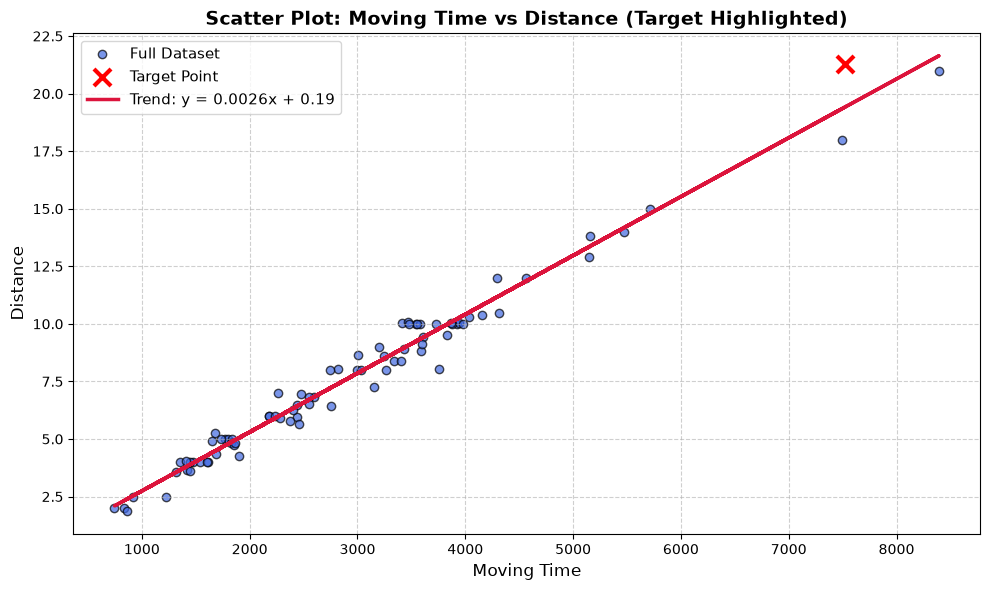

In [56]:
test_mask = df['activity_id'] == 20726316151

x_full = df.loc[~test_mask, 'moving_time']
y_full = df.loc[~test_mask, 'distance']

x_target = df.loc[test_mask, 'moving_time']
y_target = df.loc[test_mask, 'distance']

plt.figure(figsize=(10, 6))
plt.scatter(x_full, y_full, color='royalblue', alpha=0.7, edgecolors='k', label='Full Dataset')

plt.scatter(x_target, y_target, color='red', marker='x', s=150, linewidths=3, label='Target Point')

x_all = df['moving_time']
y_all = df['distance']
m, b = np.polyfit(x_all, y_all, 1)

plt.plot(x_all, m * x_all + b, color='crimson', linewidth=2.5, label=f'Trend: y = {m:.4f}x + {b:.2f}')

plt.title('Scatter Plot: Moving Time vs Distance (Target Highlighted)', fontsize=14, fontweight='bold')
plt.xlabel('Moving Time', fontsize=12)
plt.ylabel('Distance', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

#### Feature Selection

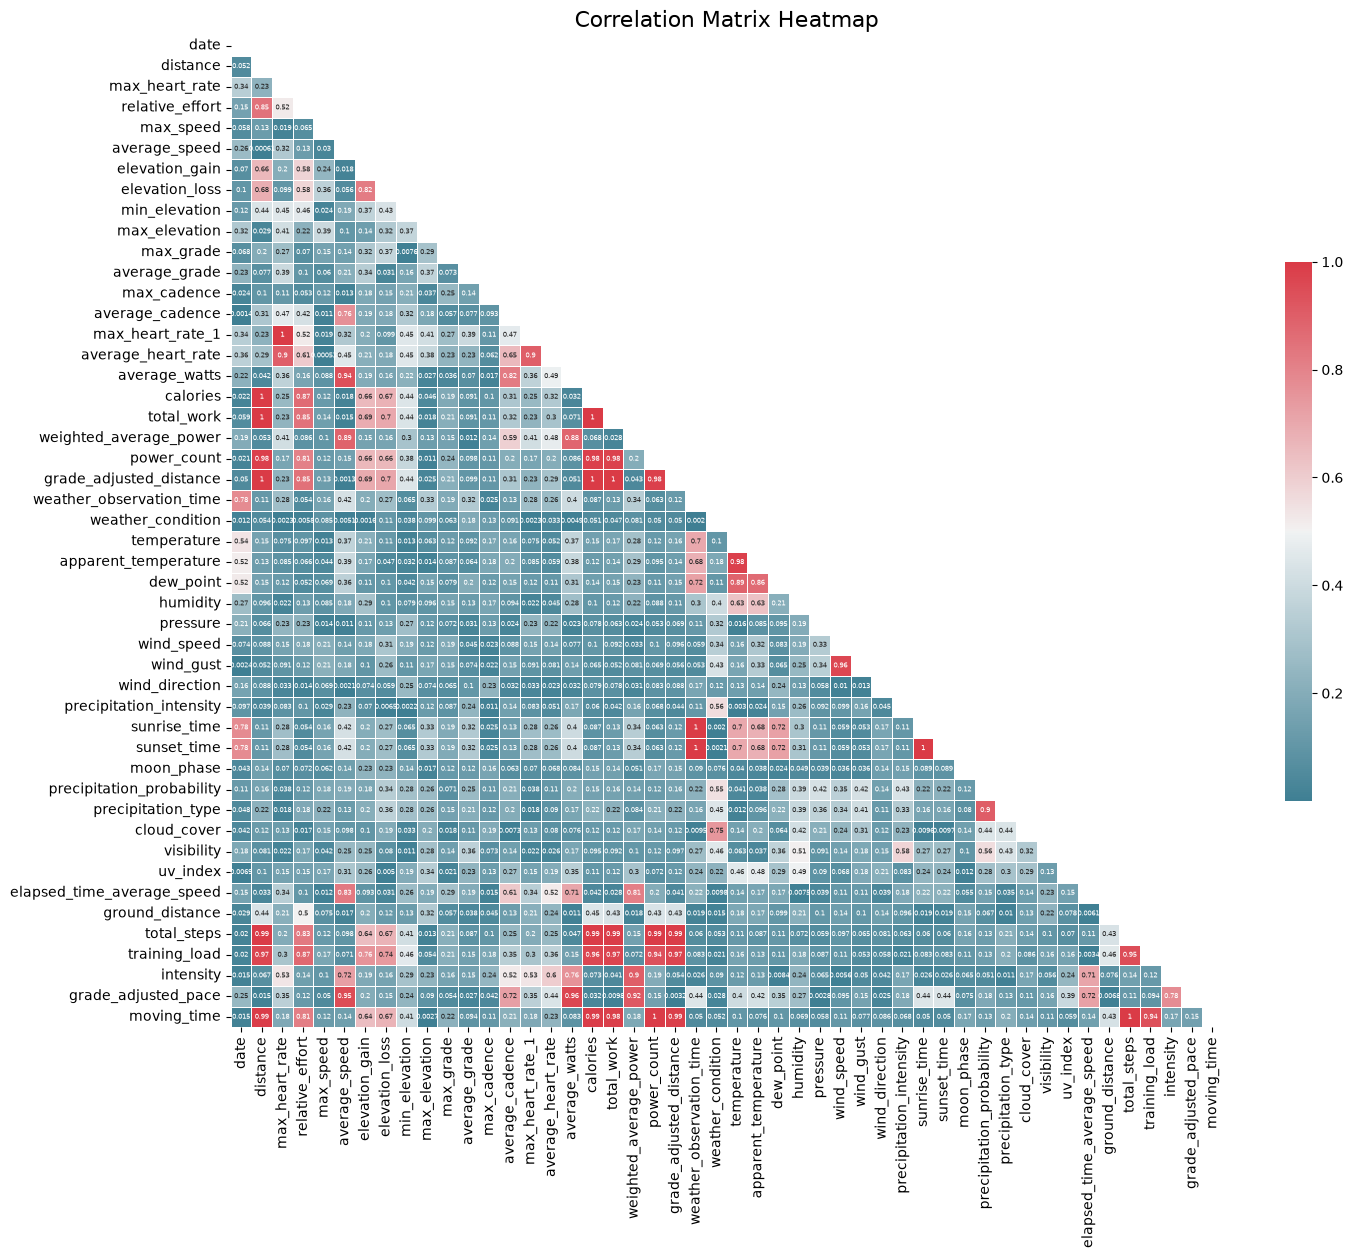

In [19]:
df_temp = x_train.copy()

df_temp["moving_time"] = y_train.values

corr = np.abs(df_temp.corr())

mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True

f, ax = plt.subplots(figsize=(16, 14))

cmap = sns.diverging_palette(220, 10, as_cmap=True)

sns.heatmap(corr, mask=mask, cmap=cmap, vmax=1, square=True, linewidths=.5, 
            cbar_kws={"shrink": .5}, annot=True, annot_kws={"size": 5})

plt.title("Correlation Matrix Heatmap", fontsize=16)
plt.show()

Remaining features count: 15


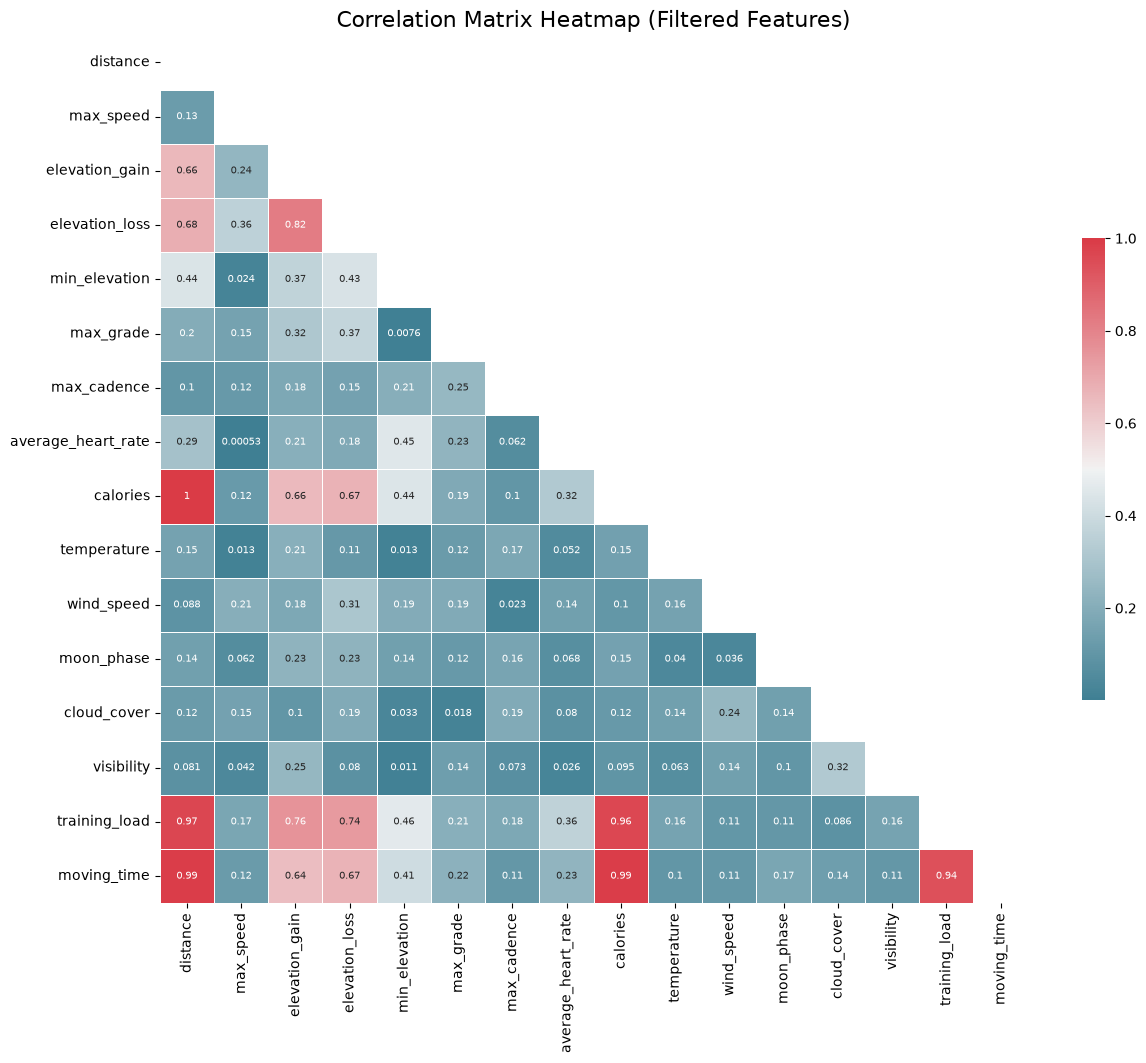

Total features shown in heatmap: 15


In [20]:
# List of features to drop based on low correlation (< 0.1) and redundancy

features_to_drop = [
    'date', 
    'max_elevation', 
    'average_grade', 
    'average_watts',
    'weather_observation_time', 
    'weather_condition', 
    'apparent_temperature',
    'dew_point', 
    'humidity', 
    'pressure', 
    'wind_gust', 
    'wind_direction',
    'precipitation_intensity', 
    'sunrise_time', 
    'sunset_time', 
    'uv_index',
    'grade_adjusted_distance', 
    'ground_distance', 
    'total_work',
    "relative_effort",
    "weighted_average_power",
    'max_heart_rate_1',
    "grade_adjusted_pace",
    'precipitation_type',
    'precipitation_probability',
    'average_cadence',
    'total_steps',
    'power_count',
    'elapsed_time_average_speed',
    "max_heart_rate",
    "intensity",
    "average_speed"
]

features = features.drop(columns=features_to_drop, errors='ignore')

print(f"Remaining features count: {features.shape[1]}")

test_mask = df['activity_id'] == 20726316151
x_train_clean = features[~test_mask]
y_train_clean = target[~test_mask]

df_temp = x_train_clean.copy()
df_temp["moving_time"] = y_train_clean.values

corr = np.abs(df_temp.corr())

mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True

f, ax = plt.subplots(figsize=(14, 12))
cmap = sns.diverging_palette(220, 10, as_cmap=True)

sns.heatmap(corr, mask=mask, cmap=cmap, vmax=1, square=True, linewidths=.5, 
            cbar_kws={"shrink": .5}, annot=True, annot_kws={"size": 7})

plt.title("Correlation Matrix Heatmap (Filtered Features)", fontsize=16)
plt.show()

print(f"Total features shown in heatmap: {x_train_clean.shape[1]}")

In [21]:
df_temp = x_train_clean.copy()
df_temp["moving_time"] = y_train_clean.values
corr_matrix = df_temp.corr().abs()

high_corr_counts = {}
for col in corr_matrix.columns:

    count = ((corr_matrix[col] > 0.5) & (corr_matrix.index != col)).sum()
    high_corr_counts[col] = count

high_corr_summary = pd.Series(high_corr_counts).sort_values(ascending=False)

print("--- Count of features with correlation > 0.5 ---")
print(high_corr_summary)

--- Count of features with correlation > 0.5 ---
distance              5
elevation_gain        5
elevation_loss        5
calories              5
moving_time           5
training_load         5
min_elevation         0
max_speed             0
average_heart_rate    0
max_cadence           0
max_grade             0
temperature           0
moon_phase            0
wind_speed            0
visibility            0
cloud_cover           0
dtype: int64


In [22]:
# KNN Model Training and Prediction
knn = KNeighborsRegressor(n_neighbors=5)

knn.fit(x_train, y_train)
y_pred = knn.predict(x_test)

# Score Evaluation
actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Predicted value: 2603.80
Actual value: 7526.00
Absolute error: 4922.20
Percentage deviation: 65.40%
Closeness Score (0 to 1): 0.3460
Closeness Percentage: 34.60%


#### Feature Scaling

In [24]:
# MinMax Scaler

test_mask = df['activity_id'] == 20726316151

x_train = features[~test_mask]
x_test = features[test_mask]
y_train = target[~test_mask]
y_test = target[test_mask]

scaler = MinMaxScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

#### ML Models

In [25]:
# TEST-TRAIN SPLIT DEFINITIVE

test_mask = df['activity_id'] == 20726316151

x_train = features[~test_mask]
x_test = features[test_mask]
y_train = target[~test_mask]
y_test = target[test_mask]

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

##### KNN

In [26]:
# KNN

knn = KNeighborsRegressor(n_neighbors=5)

knn.fit(x_train_scaled, y_train)
y_pred = knn.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Predicted value: 6263.00
Actual value: 7526.00
Absolute error: 1263.00
Percentage deviation: 16.78%
Closeness Score (0 to 1): 0.8322
Closeness Percentage: 83.22%


In [27]:
# KNN RANDOM SEARCH
knn = KNeighborsRegressor()

param_dist = {
    'n_neighbors': randint(1, 15),          
    'weights': ['uniform', 'distance'],     
    'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'], 
    'metric': ['euclidean', 'manhattan', 'minkowski']       
}

random_search_knn = RandomizedSearchCV(
    estimator=knn,
    param_distributions=param_dist,
    n_iter=20,          
    cv=5,               
    scoring='neg_mean_absolute_error', 
    random_state=42,
    n_jobs=-1           
)

random_search_knn.fit(x_train_scaled, y_train)

print(f"Best hyperparameters (KNN): {random_search_knn.best_params_}")
print(f"Best score obtained (Negative MAE): {random_search_knn.best_score_}")

best_knn = random_search_knn.best_estimator_

y_pred = best_knn.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"\n--- Test Evaluation with Best KNN ---")
print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Best hyperparameters (KNN): {'algorithm': 'kd_tree', 'metric': 'manhattan', 'n_neighbors': 4, 'weights': 'uniform'}
Best score obtained (Negative MAE): -461.55183823529416

--- Test Evaluation with Best KNN ---
Predicted value: 6400.50
Actual value: 7526.00
Absolute error: 1125.50
Percentage deviation: 14.95%
Closeness Score (0 to 1): 0.8505
Closeness Percentage: 85.05%


In [28]:
# KNN GRID SEARCH

knn = KNeighborsRegressor()

param_grid = {
    'n_neighbors': [3, 4, 5, 6, 7],         
    'weights': ['uniform', 'distance'],     
    'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'], 
    'metric': ['euclidean', 'manhattan', 'minkowski']      
}

grid_search_knn = GridSearchCV(
    estimator=knn,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search_knn.fit(x_train_scaled, y_train)

print(f"Best hyperparameters (Grid Search KNN): {grid_search_knn.best_params_}")
print(f"Best score obtained (Negative MAE): {grid_search_knn.best_score_}")

best_grid_knn = grid_search_knn.best_estimator_

y_pred_grid = best_grid_knn.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred_grid[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100
closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"\n--- Test Evaluation with Grid Search KNN ---")
print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Best hyperparameters (Grid Search KNN): {'algorithm': 'auto', 'metric': 'manhattan', 'n_neighbors': 4, 'weights': 'distance'}
Best score obtained (Negative MAE): -453.5270748341936

--- Test Evaluation with Grid Search KNN ---
Predicted value: 6683.66
Actual value: 7526.00
Absolute error: 842.34
Percentage deviation: 11.19%
Closeness Score (0 to 1): 0.8881
Closeness Percentage: 88.81%


##### Decision Tree

In [29]:
# DECISION TREE

tree_m = DecisionTreeRegressor(max_depth=10, random_state=42)

tree_m.fit(x_train_scaled, y_train)
y_pred = tree_m.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Predicted value: 5159.00
Actual value: 7526.00
Absolute error: 2367.00
Percentage deviation: 31.45%
Closeness Score (0 to 1): 0.6855
Closeness Percentage: 68.55%


In [30]:
# DECISION TREE RANDOM SEARCH
tree_m = DecisionTreeRegressor(random_state=42)

param_dist = {
    'max_depth': [None, 5, 10, 15, 20, 25, 30],   
    'min_samples_split': randint(2, 20),         
    'min_samples_leaf': randint(1, 20),           
    'max_features': [None, 'sqrt', 'log2', 1.0], 
    'criterion': ['squared_error', 'absolute_error'] 
}

random_search_tree = RandomizedSearchCV(
    estimator=tree_m,
    param_distributions=param_dist,
    n_iter=20,        
    cv=5,             
    scoring='neg_mean_absolute_error', 
    random_state=42,
    n_jobs=-1         
)

random_search_tree.fit(x_train_scaled, y_train)

print(f"Best hyperparameters (Decision Tree): {random_search_tree.best_params_}")
print(f"Best score obtained (Negative MAE): {random_search_tree.best_score_}")

best_tree = random_search_tree.best_estimator_

y_pred = best_tree.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"\n--- Test Evaluation with Best Decision Tree ---")
print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Best hyperparameters (Decision Tree): {'criterion': 'squared_error', 'max_depth': 15, 'max_features': 1.0, 'min_samples_leaf': 3, 'min_samples_split': 6}
Best score obtained (Negative MAE): -282.49683823529415

--- Test Evaluation with Best Decision Tree ---
Predicted value: 7198.33
Actual value: 7526.00
Absolute error: 327.67
Percentage deviation: 4.35%
Closeness Score (0 to 1): 0.9565
Closeness Percentage: 95.65%


In [31]:
# DECISION TREE GRID SEARCH
tree_m = DecisionTreeRegressor(random_state=42)

param_grid = {
    'max_depth': [12, 15, 18],                 
    'min_samples_split': [4, 6, 8, 10],        
    'min_samples_leaf': [2, 3, 4, 5],           
    'max_features': [1.0, 0.8, 'sqrt'],     
    'criterion': ['squared_error']             
}

grid_search_tree = GridSearchCV(
    estimator=tree_m,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search_tree.fit(x_train_scaled, y_train)

print(f"Best hyperparameters (Grid Search Decision Tree): {grid_search_tree.best_params_}")
print(f"Best score obtained (Negative MAE): {grid_search_tree.best_score_}")

best_grid_tree = grid_search_tree.best_estimator_

y_pred_grid = best_grid_tree.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred_grid[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100
closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"\n--- Test Evaluation with Grid Search Decision Tree ---")
print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Best hyperparameters (Grid Search Decision Tree): {'criterion': 'squared_error', 'max_depth': 12, 'max_features': 0.8, 'min_samples_leaf': 2, 'min_samples_split': 4}
Best score obtained (Negative MAE): -225.6057598039216

--- Test Evaluation with Grid Search Decision Tree ---
Predicted value: 7941.00
Actual value: 7526.00
Absolute error: 415.00
Percentage deviation: 5.51%
Closeness Score (0 to 1): 0.9449
Closeness Percentage: 94.49%


##### Regression Line

In [32]:
# REGRESSION LINE

lin_reg = LinearRegression()

lin_reg.fit(x_train_scaled, y_train)
y_pred = lin_reg.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Predicted value: 8669.98
Actual value: 7526.00
Absolute error: 1143.98
Percentage deviation: 15.20%
Closeness Score (0 to 1): 0.8480
Closeness Percentage: 84.80%


In [33]:
# REGRESSION LINE RANDOM SEARCH
lin_reg = LinearRegression()

param_dist = {
    'fit_intercept': [True, False],
    'positive': [True, False]
}

random_search_lin = RandomizedSearchCV(
    estimator=lin_reg,
    param_distributions=param_dist,
    n_iter=4,          
    cv=5,              
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

random_search_lin.fit(x_train_scaled, y_train)

print(f"Best hyperparameters (Linear Regression): {random_search_lin.best_params_}")
print(f"Best score obtained (Negative MAE): {random_search_lin.best_score_}")

best_lin_reg = random_search_lin.best_estimator_

y_pred = best_lin_reg.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"\n--- Test Evaluation with Best Linear Regression ---")
print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Best hyperparameters (Linear Regression): {'positive': True, 'fit_intercept': True}
Best score obtained (Negative MAE): -175.0444690124445

--- Test Evaluation with Best Linear Regression ---
Predicted value: 8484.10
Actual value: 7526.00
Absolute error: 958.10
Percentage deviation: 12.73%
Closeness Score (0 to 1): 0.8727
Closeness Percentage: 87.27%


In [34]:
# REGRESSION LINE GRID SEARCH
lin_reg = LinearRegression()

param_grid = {
    'fit_intercept': [True, False],
    'positive': [True, False]
}

grid_search_lin = GridSearchCV(
    estimator=lin_reg,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search_lin.fit(x_train_scaled, y_train)

print(f"Best hyperparameters (Grid Search Linear Regression): {grid_search_lin.best_params_}")
print(f"Best score obtained (Negative MAE): {grid_search_lin.best_score_}")

best_grid_lin_reg = grid_search_lin.best_estimator_

y_pred_grid = best_grid_lin_reg.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred_grid[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100
closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"\n--- Test Evaluation with Grid Search Linear Regression ---")
print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Best hyperparameters (Grid Search Linear Regression): {'fit_intercept': True, 'positive': True}
Best score obtained (Negative MAE): -175.0444690124445

--- Test Evaluation with Grid Search Linear Regression ---
Predicted value: 8484.10
Actual value: 7526.00
Absolute error: 958.10
Percentage deviation: 12.73%
Closeness Score (0 to 1): 0.8727
Closeness Percentage: 87.27%


##### Bagging and Pasting

In [35]:
# BAGGING AND PASTING

bag_clf = BaggingRegressor(random_state=42)

bag_clf.fit(x_train_scaled, y_train)
y_pred = bag_clf.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Predicted value: 7087.30
Actual value: 7526.00
Absolute error: 438.70
Percentage deviation: 5.83%
Closeness Score (0 to 1): 0.9417
Closeness Percentage: 94.17%


In [36]:
# BAGGING AND PASTING RANDOM SERACH
bag_clf = BaggingRegressor(random_state=42)

param_dist = {
    'n_estimators': randint(10, 200),         
    'max_samples': uniform(0.5, 0.5),         
    'max_features': uniform(0.5, 0.5),        
    'bootstrap': [True, False],                
    'bootstrap_features': [True, False]        
}

random_search_bag = RandomizedSearchCV(
    estimator=bag_clf,
    param_distributions=param_dist,
    n_iter=20,         
    cv=5,           
    scoring='neg_mean_absolute_error', 
    random_state=42,
    n_jobs=-1       
)

random_search_bag.fit(x_train_scaled, y_train)

print(f"Best hyperparameters (Bagging/Pasting): {random_search_bag.best_params_}")
print(f"Best score obtained (Negative MAE): {random_search_bag.best_score_}")

best_bag = random_search_bag.best_estimator_

y_pred = best_bag.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"\n--- Test Evaluation with Best Bagging Model ---")
print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Best hyperparameters (Bagging/Pasting): {'bootstrap': False, 'bootstrap_features': False, 'max_features': np.float64(0.982627653632069), 'max_samples': np.float64(0.8035171238433423), 'n_estimators': 50}
Best score obtained (Negative MAE): -238.52452941176472

--- Test Evaluation with Best Bagging Model ---
Predicted value: 7161.10
Actual value: 7526.00
Absolute error: 364.90
Percentage deviation: 4.85%
Closeness Score (0 to 1): 0.9515
Closeness Percentage: 95.15%


In [37]:
# BAGGING AND PASTING GRID SEARCH
bag_clf = BaggingRegressor(random_state=42)

param_grid = {
    'n_estimators': [40, 50, 60],          
    'max_samples': [0.75, 0.80, 0.85],  
    'max_features': [0.90, 0.98, 1.0],    
    'bootstrap': [False],                 
    'bootstrap_features': [False]         
}

grid_search_bag = GridSearchCV(
    estimator=bag_clf,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search_bag.fit(x_train_scaled, y_train)

print(f"Best hyperparameters (Grid Search Bagging): {grid_search_bag.best_params_}")
print(f"Best score obtained (Negative MAE): {grid_search_bag.best_score_}")

best_grid_bag = grid_search_bag.best_estimator_

y_pred_grid = best_grid_bag.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred_grid[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100
closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"\n--- Test Evaluation with Grid Search Bagging Model ---")
print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Best hyperparameters (Grid Search Bagging): {'bootstrap': False, 'bootstrap_features': False, 'max_features': 1.0, 'max_samples': 0.75, 'n_estimators': 60}
Best score obtained (Negative MAE): -226.9020833333333

--- Test Evaluation with Grid Search Bagging Model ---
Predicted value: 7129.58
Actual value: 7526.00
Absolute error: 396.42
Percentage deviation: 5.27%
Closeness Score (0 to 1): 0.9473
Closeness Percentage: 94.73%


##### Random Forest

In [38]:
# RANDOM FOREST

rf_clf = RandomForestRegressor(random_state=42)

rf_clf.fit(x_train_scaled, y_train)
y_pred = rf_clf.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Predicted value: 7135.33
Actual value: 7526.00
Absolute error: 390.67
Percentage deviation: 5.19%
Closeness Score (0 to 1): 0.9481
Closeness Percentage: 94.81%


In [39]:
# RANDOM FOREST RANDOM SEARCH
rf_clf = RandomForestRegressor(random_state=42)

param_dist = {
    'n_estimators': randint(50, 200),            
    'max_depth': [None, 10, 20, 30, 40, 50],     
    'min_samples_split': randint(2, 11),         
    'min_samples_leaf': randint(1, 11),         
    'max_features': [1.0, 'sqrt', 'log2'],        
    'bootstrap': [True, False]                
}

random_search_rf = RandomizedSearchCV(
    estimator=rf_clf,
    param_distributions=param_dist,
    n_iter=20,         
    cv=5,              
    scoring='neg_mean_absolute_error', 
    random_state=42,
    n_jobs=-1           
)

random_search_rf.fit(x_train_scaled, y_train)

print(f"Best hyperparameters (Random Forest): {random_search_rf.best_params_}")
print(f"Best score obtained (Negative MAE): {random_search_rf.best_score_}")

best_rf = random_search_rf.best_estimator_

y_pred = best_rf.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"\n--- Test Evaluation with Best Random Forest ---")
print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Best hyperparameters (Random Forest): {'bootstrap': False, 'max_depth': 40, 'max_features': 1.0, 'min_samples_leaf': 1, 'min_samples_split': 4, 'n_estimators': 157}
Best score obtained (Negative MAE): -243.47526617334802

--- Test Evaluation with Best Random Forest ---
Predicted value: 7303.13
Actual value: 7526.00
Absolute error: 222.87
Percentage deviation: 2.96%
Closeness Score (0 to 1): 0.9704
Closeness Percentage: 97.04%


In [40]:
# RANDOM FOREST GRID SERACH
rf_clf = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [140, 157, 175],      
    'max_depth': [30, 40, None],            
    'min_samples_split': [3, 4, 5],         
    'min_samples_leaf': [1, 2],            
    'max_features': [1.0],                  
    'bootstrap': [False]                     
}

grid_search_rf = GridSearchCV(
    estimator=rf_clf,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search_rf.fit(x_train_scaled, y_train)

print(f"Best hyperparameters (Grid Search Random Forest): {grid_search_rf.best_params_}")
print(f"Best score obtained (Negative MAE): {grid_search_rf.best_score_}")

best_grid_rf = grid_search_rf.best_estimator_

y_pred_grid = best_grid_rf.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred_grid[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100
closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"\n--- Test Evaluation with Grid Search Random Forest Model ---")
print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Best hyperparameters (Grid Search Random Forest): {'bootstrap': False, 'max_depth': 30, 'max_features': 1.0, 'min_samples_leaf': 2, 'min_samples_split': 3, 'n_estimators': 175}
Best score obtained (Negative MAE): -234.49629131652645

--- Test Evaluation with Grid Search Random Forest Model ---
Predicted value: 7203.50
Actual value: 7526.00
Absolute error: 322.50
Percentage deviation: 4.29%
Closeness Score (0 to 1): 0.9571
Closeness Percentage: 95.71%


##### Gradient Boost

In [41]:
# GRADIENT BOOSTING

gb_clf = GradientBoostingRegressor(random_state=42)

gb_clf.fit(x_train_scaled, y_train)
y_pred = gb_clf.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Predicted value: 7644.10
Actual value: 7526.00
Absolute error: 118.10
Percentage deviation: 1.57%
Closeness Score (0 to 1): 0.9843
Closeness Percentage: 98.43%


In [42]:
# GRADIENT BOOSTING RANDOM SEARCH
gb_clf = GradientBoostingRegressor(random_state=42)

param_dist = {
    'n_estimators': randint(50, 200),          
    'learning_rate': uniform(0.01, 0.2),       
    'max_depth': randint(3, 10),                 
    'min_samples_split': randint(2, 11),          
    'min_samples_leaf': randint(1, 11),       
    'subsample': uniform(0.6, 0.4),              
    'loss': ['squared_error', 'absolute_error']  
}

random_search_gb = RandomizedSearchCV(
    estimator=gb_clf,
    param_distributions=param_dist,
    n_iter=20,      
    cv=5,             
    scoring='neg_mean_absolute_error', 
    random_state=42,
    n_jobs=-1          
)

random_search_gb.fit(x_train_scaled, y_train)

print(f"Best hyperparameters (Gradient Boosting): {random_search_gb.best_params_}")
print(f"Best score obtained (Negative MAE): {random_search_gb.best_score_}")

best_gb = random_search_gb.best_estimator_

y_pred = best_gb.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"\n--- Test Evaluation with Best Gradient Boosting Model ---")
print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Best hyperparameters (Gradient Boosting): {'learning_rate': np.float64(0.15592123566761282), 'loss': 'absolute_error', 'max_depth': 8, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 150, 'subsample': np.float64(0.9886848381556415)}
Best score obtained (Negative MAE): -269.0829318145993

--- Test Evaluation with Best Gradient Boosting Model ---
Predicted value: 5509.12
Actual value: 7526.00
Absolute error: 2016.88
Percentage deviation: 26.80%
Closeness Score (0 to 1): 0.7320
Closeness Percentage: 73.20%


In [43]:
# GRADIENT BOOSTING GRID SEARCH
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

gb_clf = GradientBoostingRegressor(random_state=42)

param_grid = {
    'n_estimators': [150],              
    'learning_rate': [0.156],            
    'max_depth': [8],                       
    'min_samples_split': [2],           
    'min_samples_leaf': [3],            
    'subsample': [0.99, 1.0],               
    'loss': ['absolute_error']
}

grid_search_gb = GridSearchCV(
    estimator=gb_clf,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search_gb.fit(x_train_scaled, y_train)

print(f"Best hyperparameters (Grid Search Gradient Boosting): {grid_search_gb.best_params_}")
print(f"Best score obtained (Negative MAE): {grid_search_gb.best_score_}")

best_grid_gb = grid_search_gb.best_estimator_

y_pred_grid = best_grid_gb.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred_grid[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100
closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"\n--- Test Evaluation with Grid Search Gradient Boosting Model ---")
print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Best hyperparameters (Grid Search Gradient Boosting): {'learning_rate': 0.156, 'loss': 'absolute_error', 'max_depth': 8, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 150, 'subsample': 0.99}
Best score obtained (Negative MAE): -263.9113502915714

--- Test Evaluation with Grid Search Gradient Boosting Model ---
Predicted value: 5510.81
Actual value: 7526.00
Absolute error: 2015.19
Percentage deviation: 26.78%
Closeness Score (0 to 1): 0.7322
Closeness Percentage: 73.22%


##### Ada Boost

In [44]:
# ADAPTIVE BOOSTING

ada_clf = AdaBoostRegressor(random_state=42)

ada_clf.fit(x_train_scaled, y_train)
y_pred = ada_clf.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Predicted value: 7490.00
Actual value: 7526.00
Absolute error: 36.00
Percentage deviation: 0.48%
Closeness Score (0 to 1): 0.9952
Closeness Percentage: 99.52%


In [45]:
# ADABOOST RANDOM SEARCH

base_estimator = DecisionTreeRegressor(random_state=42)
ada_clf = AdaBoostRegressor(estimator=base_estimator, random_state=42)

param_dist = {
    'n_estimators': randint(50, 400),
    'learning_rate': uniform(0.01, 0.99), 
    'loss': ['linear', 'square', 'exponential'],
    'estimator__max_depth': randint(2, 7)
}

random_search = RandomizedSearchCV(
    estimator=ada_clf,
    param_distributions=param_dist,
    n_iter=25,         
    cv=5,               
    scoring='neg_mean_absolute_error', 
    random_state=42,
    n_jobs=-1           
)

random_search.fit(x_train_scaled, y_train)

print(f"Best hyperparameters (AdaBoost): {random_search.best_params_}")
print(f"Best score obtained (Negative MAE): {random_search.best_score_}")

best_ada = random_search.best_estimator_

y_pred = best_ada.predict(x_test_scaled)
actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100
closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"\n--- Test Evaluation with Best AdaBoost Model ---")
print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Best hyperparameters (AdaBoost): {'estimator__max_depth': 5, 'learning_rate': np.float64(0.1915704647548995), 'loss': 'square', 'n_estimators': 71}
Best score obtained (Negative MAE): -218.10452993697476

--- Test Evaluation with Best AdaBoost Model ---
Predicted value: 8392.00
Actual value: 7526.00
Absolute error: 866.00
Percentage deviation: 11.51%
Closeness Score (0 to 1): 0.8849
Closeness Percentage: 88.49%


In [50]:
# ADABOOST GRID SEARCH

base_estimator = DecisionTreeRegressor(random_state=42)
ada_clf = AdaBoostRegressor(estimator=base_estimator, random_state=42)

param_grid = {
    'n_estimators': [60, 71, 80],            
    'learning_rate': [0.15, 0.191, 0.25], 
    'loss': ['square'],                    
    'estimator__max_depth': [4, 5, 6]    
}

grid_search_ada = GridSearchCV(
    estimator=ada_clf,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search_ada.fit(x_train_scaled, y_train)

print(f"Best hyperparameters (Grid Search AdaBoost): {grid_search_ada.best_params_}")
print(f"Best score obtained (Negative MAE): {grid_search_ada.best_score_}")

best_grid_ada = grid_search_ada.best_estimator_

y_pred_grid = best_grid_ada.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred_grid[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100
closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"\n--- Test Evaluation with Grid Search AdaBoost Model ---")
print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Best hyperparameters (Grid Search AdaBoost): {'estimator__max_depth': 5, 'learning_rate': 0.25, 'loss': 'square', 'n_estimators': 60}
Best score obtained (Negative MAE): -226.6092431139122

--- Test Evaluation with Grid Search AdaBoost Model ---
Predicted value: 7490.00
Actual value: 7526.00
Absolute error: 36.00
Percentage deviation: 0.48%
Closeness Score (0 to 1): 0.9952
Closeness Percentage: 99.52%


##### XGBoost

In [47]:
# XGBoost
xgb_reg = XGBRegressor(random_state=42)

xgb_reg.fit(x_train_scaled, y_train)
y_pred = xgb_reg.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Predicted value: 8391.99
Actual value: 7526.00
Absolute error: 865.99
Percentage deviation: 11.51%
Closeness Score (0 to 1): 0.8849
Closeness Percentage: 88.49%


In [48]:
# XGBOOST RANDOM SEARCH
xgb_reg = XGBRegressor(random_state=42, eval_metric='mae')

param_dist = {
    'n_estimators': randint(50, 250),              
    'learning_rate': uniform(0.01, 0.2),           
    'max_depth': randint(3, 11),               
    'subsample': uniform(0.6, 0.4),             
    'colsample_bytree': uniform(0.6, 0.4),         
    'min_child_weight': randint(1, 7),    
    'gamma': uniform(0.0, 0.5)            
}

random_search_xgb = RandomizedSearchCV(
    estimator=xgb_reg,
    param_distributions=param_dist,
    n_iter=25,         
    cv=5,           
    scoring='neg_mean_absolute_error', 
    random_state=42,
    n_jobs=-1        
)

random_search_xgb.fit(x_train_scaled, y_train)

print(f"Best hyperparameters (XGBoost): {random_search_xgb.best_params_}")
print(f"Best score obtained (Negative MAE): {random_search_xgb.best_score_}")

best_xgb = random_search_xgb.best_estimator_

y_pred = best_xgb.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100

closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"\n--- Test Evaluation with Best XGBoost Model ---")
print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Best hyperparameters (XGBoost): {'colsample_bytree': np.float64(0.9570235993959911), 'gamma': np.float64(0.26967112095782536), 'learning_rate': np.float64(0.17148803103281252), 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 239, 'subsample': np.float64(0.6440207698110707)}
Best score obtained (Negative MAE): -207.06616825776942

--- Test Evaluation with Best XGBoost Model ---
Predicted value: 8358.79
Actual value: 7526.00
Absolute error: 832.79
Percentage deviation: 11.07%
Closeness Score (0 to 1): 0.8893
Closeness Percentage: 88.93%


In [66]:
# XGBOOST GRID SEARCH

xgb_reg = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)

param_grid = {
    'n_estimators': [200, 239, 300],          
    'learning_rate': [0.1, 0.1714, 0.2],  
    'max_depth': [4, 5, 6],                    
    'subsample': [0.6, 0.644, 0.8],
    'colsample_bytree': [0.8, 0.957, 1.0],
    'gamma': [0.1, 0.269, 0.5],
    'min_child_weight': [1, 3]
}

grid_search_xgb = GridSearchCV(
    estimator=xgb_reg,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search_xgb.fit(x_train_scaled, y_train)

print(f"Best hyperparameters (Grid Search XGBoost): {grid_search_xgb.best_params_}")
print(f"Best score obtained (Negative MAE): {grid_search_xgb.best_score_}")

best_grid_xgb = grid_search_xgb.best_estimator_
y_pred_grid = best_grid_xgb.predict(x_test_scaled)

actual_value = y_test.values[0]
predicted_value = y_pred_grid[0]

absolute_error = abs(predicted_value - actual_value)
percentage_error = (absolute_error / abs(actual_value)) * 100
closeness_score = max(0.0, 1.0 - (percentage_error / 100.0))
closeness_percentage = closeness_score * 100

print(f"\n--- Test Evaluation with Grid Search XGBoost Model ---")
print(f"Predicted value: {predicted_value:.2f}")
print(f"Actual value: {actual_value:.2f}")
print(f"Absolute error: {absolute_error:.2f}")
print(f"Percentage deviation: {percentage_error:.2f}%")
print(f"Closeness Score (0 to 1): {closeness_score:.4f}")
print(f"Closeness Percentage: {closeness_percentage:.2f}%")

Best hyperparameters (Grid Search XGBoost): {'colsample_bytree': 0.957, 'gamma': 0.269, 'learning_rate': 0.2, 'max_depth': 4, 'min_child_weight': 1, 'n_estimators': 300, 'subsample': 0.6}
Best score obtained (Negative MAE): -201.09673565135282

--- Test Evaluation with Grid Search XGBoost Model ---
Predicted value: 8298.66
Actual value: 7526.00
Absolute error: 772.66
Percentage deviation: 10.27%
Closeness Score (0 to 1): 0.8973
Closeness Percentage: 89.73%
